In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "4" else os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

if 'google.colab' in str(get_ipython()):
    print("Google Colab 環境を検出しました。環境構築を開始します...")
    if not os.path.exists("study-mikanos"):
        !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    !cmake -B build -S . > /dev/null && cmake --build build --target ch04_drawing_pixels_sim > /dev/null
    print("セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    print(f"ローカル実行環境です。(リポジトリルート: {repo_root})")


ローカル実行環境です。(リポジトリルート: /home/student/Documents/GitHub/study-mikanos)


# 4.2 ピクセルを自在に描く (`Drawing Pixels Freely and ABI`)
## 『ゼロからのOS自作入門』 第4章 ピクセル描画とmake入門 (`osbook_day04b`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/4/4.2_Drawing_Pixels_Freely_and_ABI.ipynb)

---

### 🎯 本節の学習目標 (Learning Objectives)

1. **情報カプセル化への転換**: なぜ前節（3.5節 `osbook_day03c`）の `KernelMain(uint64_t base, uint64_t size)` では2次元描画が不可能なのか、その本質的限界（解像度・ストライド・ピクセルフォーマットの欠落、引数爆発）を理解する。
2. **`FrameBufferConfig` 構造体の設計とメモリ配置**: VRAM物理ポインタ、スキャンラインストライド（*PixelsPerScanLine*）、有効解像度（*Horizontal/Vertical Resolution*）、画素形式（*PixelFormat*）を束ねる構造体の 64ビットアライメント数理（`sizeof == 24` バイト）を導出する。
3. **2次元座標からVRAM物理アドレスへの写像数理**: 2次元座標 $(x, y)$ を1次元線形アドレスへ変換する公式 $\text{Offset} = 4 \times (y \times \text{stride} + x)$ を数理的に導出し、行末パディングが存在するハードウェアでも歪まず描画できる理由を解明する。
4. **画素フォーマットの差異吸収**: RGB形式（`kPixelRGBResv8BitPerColor`）と BGR形式（`kPixelBGRResv8BitPerColor`）における 4バイトクアッドワードのカラーチャンネル並び順と予約バイトの仕様を把握する。
5. **自在な図形描画アルゴリズム**: `osbook_day04b` で導入された画面全域の白クリア（*White Screen Clear*）および任意座標・サイズへの矩形描画（*Filled Rectangle Drawing* @ $(100, 100), 200 \times 100$）の二重ループ制御を実装・検証する。
6. **コラム 4.1：ABI (*Application Binary Interface*) 徹底解剖**:
   - API（ソースレベル互換）と ABI（バイナリ・レジスタ・スタックレベル互換）の決定的な相違。
   - **System V AMD64 ABI**（Linux/カーネル）と **Microsoft x64 ABI**（Windows/UEFI）の呼び出し規約比較。
   - 引数レジスタ（`RDI, RSI, RDX, RCX, R8, R9` vs `RCX, RDX, R8, R9`）の順序差。
   - カリーセーブレジスタ（*Callee-saved* / 保存義務）と スクラッチレジスタ（*Caller-saved* / 揮発性）における `RDI`/`RSI` の役割逆転。
   - シャドウスペース（*Shadow Space* 32バイト）と レッドゾーン（*Red Zone* 128バイト）の機構。
   - 【最大の謎解き】ブートローダ（`MikanLoaderPkg/Main.c`）のカーネル関数ポインタ型宣言で、なぜ `EFIAPI` を省略しなければならないのか？ その真相と落とし穴をアセンブリレベルで解明する。


## 1. なぜ `KernelMain(base, size)` では駄目なのか？（動機と課題）

第3章（3.5節 `osbook_day03c`）において、ブートローダからカーネルへの引数引き渡しは次のように記述されていました：

```cpp
// 3.5節 (osbook_day03c) でのカーネルシグネチャ
extern "C" void KernelMain(uint64_t frame_buffer_base, uint64_t frame_buffer_size);
```

このインターフェースは、「VRAM の先頭から末尾まで全メモリをベタ塗りする（`frame_buffer[i] = i % 256`）」という単純な実験には十分でした。しかし、GUI やウィンドウシステム、テキスト文字を描画するためには、**決定的な4つの限界**に直面します。

```text
+------------------------------------------------------------------------------------------------+
|                 KernelMain(base, size) が抱えていた 4大限界 (Architectural Limitations)        |
+------------------------------------------------------------------------------------------------+
| 1. 縦横の解像度が不明                                                                          |
|    画面の幅 (HorizontalResolution) と高さ (VerticalResolution) を知らないため、                |
|    「(x, y) = (100, 100) に点を打つ」「画面中央にウィンドウを出す」といった2次元制御が不可能。 |
|                                                                                                |
| 2. スキャンライン・ストライド (PixelsPerScanLine) が不明                                        |
|    ハードウェアの制約上、1行のピクセル数には不可視パディングが含まれることがある。              |
|    幅だけで行送りを計算すると、行が進むごとにズレが蓄積し、描画が斜めに歪んで崩壊する！         |
|                                                                                                |
| 3. 画素の色配置 (PixelFormat) が不明                                                           |
|    ディスプレイやグラフィックカードによって、VRAM 上のバイト並びが RGB なのか BGR なのか不明。 |
|    赤色を出したつもりが青色になってしまう。                                                    |
|                                                                                                |
| 4. 引数リストの爆発 (Argument Explosion)                                                       |
|    これらを個別に渡そうとすると KernelMain(base, size, stride, width, height, format, ...)   |
|    と引数が膨張し、呼び出し規約やメンテナンス性が破綻する。                                     |
+------------------------------------------------------------------------------------------------+
```

この課題を解決するため、MikanOS では画面描画に必要なすべてのハードウェア属性を**単一の構造体 `struct FrameBufferConfig`** にカプセル化し、そのポインタ1つをカーネルへ引き渡す設計へと進化させます。


## 2. `FrameBufferConfig` 構造体とメモリレイアウト

### 2.1 ヘッダファイル `kernel/frame_buffer_config.hpp`

公式リポジトリのタグ `osbook_day04b` で新規導入された `kernel/frame_buffer_config.hpp` の完全なコードは以下の通りです：

```cpp
#pragma once

#include <stdint.h>

enum PixelFormat {
  kPixelRGBResv8BitPerColor,
  kPixelBGRResv8BitPerColor,
};

struct FrameBufferConfig {
  uint8_t* frame_buffer;
  uint32_t pixels_per_scan_line;
  uint32_t horizontal_resolution;
  uint32_t vertical_resolution;
  enum PixelFormat pixel_format;
};
```

ブートローダ側（`MikanLoaderPkg/Main.c`）からもこの同一定義を参照するため、`MikanLoaderPkg/frame_buffer_config.hpp` からシンボリックリンクが張られています。

---

### 2.2 64ビットアーキテクチャにおける構造体メモリレイアウトとアライメント数理

C/C++ において、構造体のサイズはメンバのバイト数の単純な合計になるとは限りません。CPU のメモリアクセス効率を最大化するため、コンパイラは**アライメント（整列）規則**に従ってパディング（詰め物）を挿入します。

64ビット x86-64 アーキテクチャにおける各メンバの配置を検証してみましょう：

| メンバ名 | C++ 型 | サイズ | アライメント要件 | オフセット範囲 |
|---|---|:---:|:---:|:---:|
| `frame_buffer` | `uint8_t*` (ポインタ) | 8 バイト | 8 バイト境界 | `0x00` 〜 `0x07` (8B) |
| `pixels_per_scan_line` | `uint32_t` | 4 バイト | 4 バイト境界 | `0x08` 〜 `0x0B` (4B) |
| `horizontal_resolution` | `uint32_t` | 4 バイト | 4 バイト境界 | `0x0C` 〜 `0x0F` (4B) |
| `vertical_resolution` | `uint32_t` | 4 バイト | 4 バイト境界 | `0x10` 〜 `0x13` (4B) |
| `pixel_format` | `enum PixelFormat` | 4 バイト | 4 バイト境界 | `0x14` 〜 `0x17` (4B) |

$$\text{Total Active Bytes} = 8 + 4 + 4 + 4 + 4 = 24 \text{ バイト}$$

構造体全体の要求アライメントは、メンバ内の最大アライメントである `uint8_t*` の **8 バイト** です。
合計バイト数 $24$ は $24 \pmod 8 = 0$ と 8 の倍数にちょうど一致するため、**末尾パディングは 0 バイト** となり、`sizeof(FrameBufferConfig) == 24` と極めて無駄のないメモリ配置となります！

---

### 2.3 UEFI ブートローダ側での構築と引数引き渡し

`MikanLoaderPkg/Main.c` では、UEFI GOP (*Graphics Output Protocol*) から取得した情報を `FrameBufferConfig` に詰め込み、カーネルエントリポイントへ渡します：

```c
// MikanLoaderPkg/Main.c (osbook_day04b)
struct FrameBufferConfig config = {
  (UINT8*)gop->Mode->FrameBufferBase,
  gop->Mode->Info->PixelsPerScanLine,
  gop->Mode->Info->HorizontalResolution,
  gop->Mode->Info->VerticalResolution,
  0
};
switch (gop->Mode->Info->PixelFormat) {
  case PixelRedGreenBlueReserved8BitPerColor:
    config.pixel_format = kPixelRGBResv8BitPerColor;
    break;
  case PixelBlueGreenRedReserved8BitPerColor:
    config.pixel_format = kPixelBGRResv8BitPerColor;
    break;
  default:
    Print(L"Unimplemented pixel format: %d\n", gop->Mode->Info->PixelFormat);
    Halt();
}

typedef void EntryPointType(const struct FrameBufferConfig*);
EntryPointType* entry_point = (EntryPointType*)entry_addr;
entry_point(&config);
```

未対応のピクセルフォーマット（ビットマスク形式など）が検出された場合は、画面が異常描画される前に `Halt()` で安全に停止させる防御的設計となっています。


In [2]:
from common import FrameBufferConfigSim, PixelFormat

# FrameBufferConfig 構造体のメモリレイアウトとアライメントを検証
sample_config = FrameBufferConfigSim(
    frame_buffer_base=0x8000_0000,
    pixels_per_scan_line=1024,
    horizontal_resolution=800,
    vertical_resolution=600,
    pixel_format=PixelFormat.RGB_RESV_8BIT_PER_COLOR
)

print(f"■ FrameBufferConfig 構造体サイズ: {sample_config.STRUCT_SIZE} バイト")
print("■ 各フィールドのオフセットと型:")
for field_name, (offset, size, type_str) in sample_config.FIELD_OFFSETS.items():
    print(f"  +0x{offset:02X} | {size:2d} Bytes | {type_str:25s} | {field_name}")

print(f"\n■ スキャンラインストライド: {sample_config.pixels_per_scan_line} px")
print(f"■ 有効水平解像度:         {sample_config.horizontal_resolution} px")
print(f"■ 行末パディング:         {sample_config.get_stride_padding_pixels()} px (不可視領域)")
print(f"■ 必要総 VRAM バッファ量: {sample_config.total_buffer_size_bytes() / (1024*1024):.2f} MiB")


■ FrameBufferConfig 構造体サイズ: 24 バイト
■ 各フィールドのオフセットと型:
  +0x00 |  8 Bytes | uint8_t*                  | frame_buffer
  +0x08 |  4 Bytes | uint32_t                  | pixels_per_scan_line
  +0x0C |  4 Bytes | uint32_t                  | horizontal_resolution
  +0x10 |  4 Bytes | uint32_t                  | vertical_resolution
  +0x14 |  4 Bytes | enum PixelFormat          | pixel_format

■ スキャンラインストライド: 1024 px
■ 有効水平解像度:         800 px
■ 行末パディング:         224 px (不可視領域)
■ 必要総 VRAM バッファ量: 2.34 MiB


## 3. 2次元座標 $(x, y)$ から VRAM 物理アドレスへの写像数理

### 3.1 座標計算の数学的定式化

画面上の任意の点 $(x, y)$（ただし $0 \le x < \text{horizontal\_resolution}$, $0 \le y < \text{vertical\_resolution}$）を指定してピクセルを描画する場合、VRAM 上のリニアなメモリオフセットを正確に計算する必要があります。

```text
VRAM 2次元平面:
  (0, 0) ---------------------------------> X (horizontal_resolution)
    |   [Pixel 0,0] [Pixel 1,0] ... [Pixel W-1, 0] | [Padding ... Stride-1]
    |   [Pixel 0,1] [Pixel 1,1] ... [Pixel W-1, 1] | [Padding ... Stride-1]
    v   ...
    Y (vertical_resolution)
```

1. **ピクセルの通算インデックス $\text{Index}(x, y)$**:
   1行あたりにはパディングを含む `pixels_per_scan_line` 個のピクセルが並んでいるため、
   $$\text{Index}(x, y) = y \times \text{pixels\_per\_scan\_line} + x$$

2. **バイトオフセット $\text{ByteOffset}(x, y)$**:
   UEFI GOP では 1 ピクセルあたり 4 バイト（32 ビット）固定であるため、
   $$\text{ByteOffset}(x, y) = 4 \times \text{Index}(x, y) = 4 \times (y \times \text{pixels\_per\_scan\_line} + x)$$

3. **VRAM 物理アドレス $\text{Address}(x, y)$**:
   $$\text{Address}(x, y) = \text{frame\_buffer} + 4 \times (y \times \text{pixels\_per\_scan\_line} + x)$$

> [!WARNING]
> **よくある落とし穴：$y \times \text{horizontal\_resolution} + x$ による計算ミス**
> もし `pixels_per_scan_line` ではなく `horizontal_resolution` を掛けてしまうと、行末のパディング（例：$1024 - 800 = 224$ ピクセル）が無視されます。
> その結果、行が進むごとに 224 ピクセル分のオフセットが累積して左方向へズレていき、画面全体が激しく斜めに歪むバグが発生します！

---

### 3.2 画素フォーマット (RGB vs BGR) と 4バイトクアッドワード

計算されたアドレスにある 4 バイトのメモリ領域に対し、RGB 各色をどのように書き込むかは `config.pixel_format` に依存します：

```text
RGB 形式 (kPixelRGBResv8BitPerColor):
  Address + 0: 赤 (Red: 8bit, 0〜255)
  Address + 1: 緑 (Green: 8bit, 0〜255)
  Address + 2: 青 (Blue: 8bit, 0〜255)
  Address + 3: 予約領域 (Reserved: 0)

BGR 形式 (kPixelBGRResv8BitPerColor):
  Address + 0: 青 (Blue: 8bit, 0〜255)
  Address + 1: 緑 (Green: 8bit, 0〜255)
  Address + 2: 赤 (Red: 8bit, 0〜255)
  Address + 3: 予約領域 (Reserved: 0)
```

### 3.3 `WritePixel` 関数の実装解読

`kernel/main.cpp` で定義された `WritePixel` 関数は以下の通りです：

```cpp
struct PixelColor {
  uint8_t r, g, b;
};

int WritePixel(const FrameBufferConfig& config,
               int x, int y, const PixelColor& c) {
  const int pixel_position = config.pixels_per_scan_line * y + x;
  if (config.pixel_format == kPixelRGBResv8BitPerColor) {
    uint8_t* p = &config.frame_buffer[4 * pixel_position];
    p[0] = c.r;
    p[1] = c.g;
    p[2] = c.b;
  } else if (config.pixel_format == kPixelBGRResv8BitPerColor) {
    uint8_t* p = &config.frame_buffer[4 * pixel_position];
    p[0] = c.b;
    p[1] = c.g;
    p[2] = c.r;
  } else {
    return -1;
  }
  return 0;
}
```


In [3]:
from common import PixelColorSim

# RGB と BGR でのバイト配列変換を検証
color = PixelColorSim(r=0xAA, g=0xBB, b=0xCC)

bytes_rgb = color.to_bytes(PixelFormat.RGB_RESV_8BIT_PER_COLOR)
bytes_bgr = color.to_bytes(PixelFormat.BGR_RESV_8BIT_PER_COLOR)

print(f"元カラー: R=0x{color.r:02X}, G=0x{color.g:02X}, B=0x{color.b:02X}")
print(f"kPixelRGBResv8BitPerColor メモリ配列: [0x{bytes_rgb[0]:02X}, 0x{bytes_rgb[1]:02X}, 0x{bytes_rgb[2]:02X}, 0x{bytes_rgb[3]:02X}] (R, G, B, 0)")
print(f"kPixelBGRResv8BitPerColor メモリ配列: [0x{bytes_bgr[0]:02X}, 0x{bytes_bgr[1]:02X}, 0x{bytes_bgr[2]:02X}, 0x{bytes_bgr[3]:02X}] (B, G, R, 0)")


元カラー: R=0xAA, G=0xBB, B=0xCC
kPixelRGBResv8BitPerColor メモリ配列: [0xAA, 0xBB, 0xCC, 0x00] (R, G, B, 0)
kPixelBGRResv8BitPerColor メモリ配列: [0xCC, 0xBB, 0xAA, 0x00] (B, G, R, 0)


## 4. `day04b` カーネル描画アルゴリズムの完全解剖

`kernel/main.cpp` のエントリポイント `KernelMain` では、新設した `WritePixel` 関数を用いて画面全体の白クリアと緑色矩形の描画を行います：

```cpp
// kernel/main.cpp (osbook_day04b)
extern "C" void KernelMain(const FrameBufferConfig& frame_buffer_config) {
  // 1. 画面全体を白 (255, 255, 255) で塗りつぶす
  for (int x = 0; x < frame_buffer_config.horizontal_resolution; ++x) {
    for (int y = 0; y < frame_buffer_config.vertical_resolution; ++y) {
      WritePixel(frame_buffer_config, x, y, {255, 255, 255});
    }
  }

  // 2. (100, 100) の位置に横200 × 縦100 の緑色長方形 (0, 255, 0) を描画
  for (int x = 0; x < 200; ++x) {
    for (int y = 0; y < 100; ++y) {
      WritePixel(frame_buffer_config, 100 + x, 100 + y, {0, 255, 0});
    }
  }

  // 3. 処理完了後、HLT 命令で CPU を省電力停止
  while (1) __asm__("hlt");
}
```

- **二重ループによる矩形描画**:
  外側ループで $x$、内側ループで $y$ を回すことで、指定矩形領域内のすべてのピクセルに対して `WritePixel` を呼び出します。
- **CPU 省電力命令 `HLT`**:
  描画完了後、ビジーループ（`while(1);`）で CPU 使用率 100% のまま浪費させるのではなく、`HLT` 命令を発行して割り込み待ちの省電力スリープ状態に落とします。


/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12524 (\N{KATAKANA LETTER RE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12531 (\N{KATAKANA LETTER N}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12480 (\N{KATAKANA LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12522 (\N{KATAKANA LETTER RI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: Us

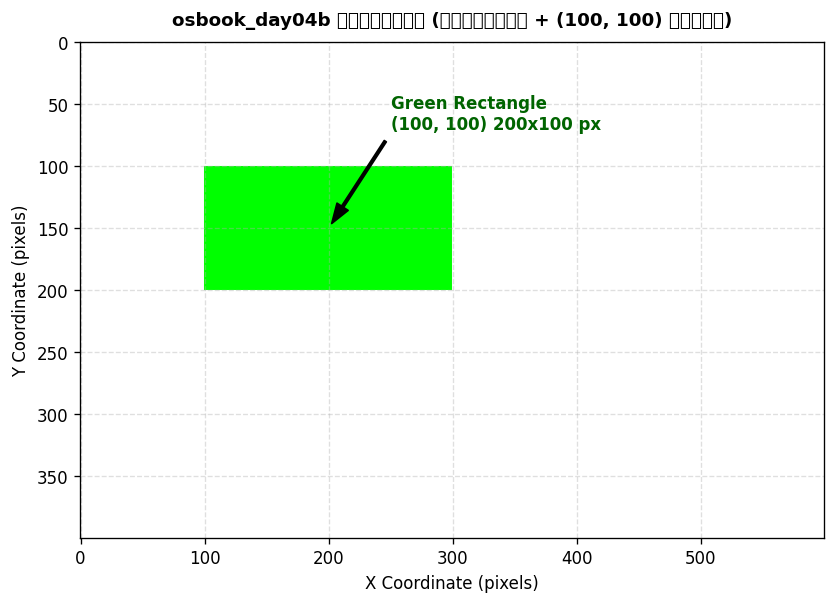

In [4]:
import matplotlib.pyplot as plt
from common import WritePixelSimulator

# osbook_day04b の描画シーケンスを完全シミュレーション
sim_cfg = FrameBufferConfigSim(
    frame_buffer_base=0x8000_0000,
    pixels_per_scan_line=600,
    horizontal_resolution=600,
    vertical_resolution=400,
    pixel_format=PixelFormat.RGB_RESV_8BIT_PER_COLOR
)
sim = WritePixelSimulator(sim_cfg)
sim.execute_day04b_demo()

# レンダリング結果を NumPy RGB 配列として取得
frame_img = sim.to_rgb_numpy()

plt.figure(figsize=(8, 5.5), dpi=120)
plt.imshow(frame_img, origin="upper")
plt.title("osbook_day04b レンダリング結果 (画面全域白クリア + (100, 100) 緑色長方形)", fontsize=11, fontweight="bold", pad=10)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.annotate("Green Rectangle\n(100, 100) 200x100 px", xy=(200, 150), xytext=(250, 70),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=10, fontweight="bold", color="darkgreen")
plt.show()


## 5. コラム 4.1：ABI (*Application Binary Interface*) 徹底解剖

### 5.1 API と ABI の決定的な違い

低レイヤや OS 自作の世界において、**API** (*Application Programming Interface*) と **ABI** (*Application Binary Interface*) の混同は致命的なバグや理解不足を招きます。

```text
+-------------------+-----------------------------------------------------------------------------+
| 比較項目          | API (Application Programming Interface)                                     |
+-------------------+-----------------------------------------------------------------------------+
| 契約レベル        | ソースコード・言語レベル (C/C++ ヘッダ、関数名、引数の型名)                |
| 互換性の維持      | 再コンパイルによって互換性が保たれる (Compile-time Compatibility)           |
| 例                | int WritePixel(const FrameBufferConfig&, int, int, const PixelColor&);      |
+-------------------+-----------------------------------------------------------------------------+
| 比較項目          | ABI (Application Binary Interface)                                         |
+-------------------+-----------------------------------------------------------------------------+
| 契約レベル        | 機械語・バイナリ・ハードウェアレベル (レジスタ割り当て、スタック、呼出規約) |
| 互換性の維持      | 再コンパイルなしでバイナリ同士が直接結合できる (Link/Run-time Compatibility)|
| 例                | 第1引数は RDI レジスタか RCX レジスタか？ 呼出側がスタックを掃除するか？     |
+-------------------+-----------------------------------------------------------------------------+
```

---

### 5.2 x86-64 アーキテクチャの 2大呼出規約（Calling Conventions）

x86-64 の世界には、互換性のない2つの巨大な呼出規約が存在します：

1. **System V AMD64 ABI**:
   - 採用環境: Linux, FreeBSD, macOS, Solaris, そして **MikanOS カーネル**
   - 整数・ポインタ引数は最大 6 個まで CPU レジスタで渡す：`RDI, RSI, RDX, RCX, R8, R9`
2. **Microsoft x64 ABI**:
   - 採用環境: Microsoft Windows, および **UEFI ファームウェア (EDK II)**
   - 整数・ポインタ引数は最大 4 個まで CPU レジスタで渡す：`RCX, RDX, R8, R9`

```text
引数レジスタ割り当て順序の比較対照表:
+-----------+---------------------------------+---------------------------------+
| 引数順序  | System V AMD64 ABI (MikanOS)    | Microsoft x64 ABI (UEFI / Win)  |
+-----------+---------------------------------+---------------------------------+
| 第1引数   | RDI                             | RCX   <-- ★致命的な不一致！    |
| 第2引数   | RSI                             | RDX   <-- ★致命的な不一致！    |
| 第3引数   | RDX                             | R8                              |
| 第4引数   | RCX                             | R9                              |
| 第5引数   | R8                              | スタック [RSP + 0x28]           |
| 第6引数   | R9                              | スタック [RSP + 0x30]           |
| 7個目以降 | スタック [RSP + 0x08...]        | スタック [RSP + 0x38...]        |
+-----------+---------------------------------+---------------------------------+
```

---

### 5.3 レジスタ保護責任の違い（Callee-saved vs Caller-saved）

呼出規約は引数の渡し方だけでなく、「関数呼び出しによって壊してよいレジスタ（揮発性）」と「元の値を保持・復元しなければならないレジスタ（不揮発性）」の責任境界も規定しています。

ここで最も劇的かつ危険な相違点が **`RDI` と `RSI` の扱い** です：

- **Microsoft x64 ABI**:
  `RDI` と `RSI` は **Callee-saved (Preserved / 非揮発性)**！
  関数側がこれらを使う場合、関数の先頭で `PUSH` し、終了時に `POP` して元通り復元する責任を負います。
- **System V AMD64 ABI**:
  `RDI` と `RSI` は **Caller-saved (Volatile / 揮発性引数レジスタ)**！
  関数側はこれらを第1引数・第2引数として自由に上書き・破壊して構いません。

もし MS ABI で動くプログラムが System V ABI の関数を直接呼ぶと、MS ABI 側が「壊されないはず」と信じていた `RDI` / `RSI` の値が破壊され、呼び出し元に戻った瞬間に不可解なクラッシュに見舞われます。

---

### 5.4 特殊スタック領域：シャドウスペース vs レッドゾーン

1. **シャドウスペース (*Shadow Space* / *Home Space* - Microsoft x64 ABI)**:
   - 呼出側（Caller）は、関数を `CALL` する直前にスタック上に **32バイト（4×8バイト）の空き領域** を必ず確保しなければなりません。
   - これは、関数側が引数レジスタ `RCX, RDX, R8, R9` をメモリ上に即座に退避できるように用意された専用スペースです。
   - 引数が 0 個や 1 個の関数であっても、**32バイトの確保は絶対義務** です。
2. **レッドゾーン (*Red Zone* - System V AMD64 ABI)**:
   - `RSP` の下位 **128バイト**（`[RSP - 128]` 〜 `[RSP - 1]`）の一時領域。
   - 他の関数を呼ばない末端関数（Leaf Function）において、`SUB RSP, ...` や `ADD RSP, ...` のスタック確保・解放命令を省略してレジスタを退避し、劇的な高速化を図る機構。
   - **カーネルでの注意**: ハードウェア割り込みが発生すると、CPU はスタックポインタ `RSP` の下に割り込みフレーム（RIP, CS, RFLAGS 等）を強制プッシュするため、レッドゾーンの内容が非同期に破壊されます！ そのため、OS カーネルビルドでは **`-mno-red-zone` が絶対必須** です。

---

### 5.5 【核心】ブートローダからカーネルへの移行で『EFIAPI』を省略する真相

ブートローダ（`MikanLoaderPkg/Main.c`）は UEFI アプリケーションであるため、UEFI ファームウェアからは **Microsoft x64 ABI** で呼び出されます。

一方、カーネル（`KernelMain`）はベアメタルの ELF64 バイナリであり、Clang の既定である **System V AMD64 ABI** でコンパイルされています。

では、なぜ `Main.c` は特別なアセンブリスタブを使わずに、C言語から直接 `KernelMain` を呼べるのでしょうか？

その秘密は、`Main.c` における関数ポインタの宣言にあります：

```c
// MikanLoaderPkg/Main.c
typedef void EntryPointType(const struct FrameBufferConfig*);
EntryPointType* entry_point = (EntryPointType*)entry_addr;
entry_point(&config);
```

#### なぜ `EFIAPI` を付けてはいけないのか？

EDK II のヘッダ定義において、`EFIAPI` マクロは Linux/GCC/Clang 環境では次のように展開されます：

```c
#define EFIAPI __attribute__((ms_abi))
```

- **もし `EFIAPI` を付けた場合**:
  `typedef void EFIAPI EntryPointType(...)`
  コンパイラ（Clang）は「この関数ポインタ呼び出しは Microsoft x64 ABI に従う」と判断し、第1引数 `&config` を **`RCX`** レジスタに格納して `CALL` します。
  しかし、受け側の `KernelMain` は System V ABI なので、第1引数を **`RDI`** レジスタから取得しようとします！
  その結果、`KernelMain` は未初期化のゴミ値アドレスを `frame_buffer_config` として参照し、最初の `WritePixel` で即座に **ページフォルト (`#PF`) クラッシュ** します！
- **`EFIAPI` を省略した場合（MikanOS の解法）**:
  Clang on Linux はホストの規定である **System V AMD64 ABI** に従ってコードを生成します。
  そのため、呼出元の `Main.c` は第1引数 `&config` を正しく **`RDI`** レジスタに格納して `CALL` します。
  カーネル側も `RDI` から引数を読み取るため、**両者の ABI が完全に一致し、無事に起動できる** のです！


In [5]:
from common import AbiComparisonAnalyzer, AbiKind

# System V ABI と Microsoft x64 ABI の仕様比較
sysv_spec = AbiComparisonAnalyzer.get_spec(AbiKind.SYSTEM_V_AMD64)
ms_spec = AbiComparisonAnalyzer.get_spec(AbiKind.MICROSOFT_X64)

print("■ 引数レジスタ順序比較:")
print(f"  System V AMD64:  {sysv_spec.integer_arg_registers}")
print(f"  Microsoft x64:   {ms_spec.integer_arg_registers}")

print("\n■ シャドウスペース & レッドゾーン比較:")
print(f"  System V AMD64:  シャドウスペース={sysv_spec.shadow_space_bytes}B, レッドゾーン={sysv_spec.red_zone_bytes}B")
print(f"  Microsoft x64:   シャドウスペース={ms_spec.shadow_space_bytes}B, レッドゾーン={ms_spec.red_zone_bytes}B")

print("\n■ Callee-saved (保護義務) レジスタ比較:")
print(f"  System V AMD64:  {sysv_spec.callee_saved_registers}")
print(f"  Microsoft x64:   {ms_spec.callee_saved_registers}")

# UEFI -> カーネル移行時のシミュレーション
print("\n■ MikanLoaderPkg -> KernelMain 呼出時の ABI 検証:")
for use_efiapi in [False, True]:
    result = AbiComparisonAnalyzer.analyze_uefi_kernel_bridge(use_efiapi)
    status = "✅ 成功 (COMPATIBLE)" if result["is_compatible"] else "❌ 爆死 (MISMATCH)"
    print(f"  [use_efiapi={use_efiapi}] -> {status}")
    print(f"    呼出規約:     {result['caller_convention']}")
    print(f"    渡される場所: {result['passed_in_register']}  <->  期待される場所: {result['expected_in_register']}")
    print(f"    動作結果:     {result['consequence']}\n")


■ 引数レジスタ順序比較:
  System V AMD64:  ['RDI', 'RSI', 'RDX', 'RCX', 'R8', 'R9']
  Microsoft x64:   ['RCX', 'RDX', 'R8', 'R9']

■ シャドウスペース & レッドゾーン比較:
  System V AMD64:  シャドウスペース=0B, レッドゾーン=128B
  Microsoft x64:   シャドウスペース=32B, レッドゾーン=0B

■ Callee-saved (保護義務) レジスタ比較:
  System V AMD64:  ['RBX', 'RSP', 'RBP', 'R12', 'R13', 'R14', 'R15']
  Microsoft x64:   ['RBX', 'RBP', 'RDI', 'RSI', 'RSP', 'R12', 'R13', 'R14', 'R15']

■ MikanLoaderPkg -> KernelMain 呼出時の ABI 検証:
  [use_efiapi=False] -> ✅ 成功 (COMPATIBLE)
    呼出規約:     System V AMD64 ABI (by omitting EFIAPI)
    渡される場所: RDI  <->  期待される場所: RDI
    動作結果:     KernelMain correctly reads FrameBufferConfig pointer from RDI. OS boots successfully.

  [use_efiapi=True] -> ❌ 爆死 (MISMATCH)
    呼出規約:     Microsoft x64 ABI (due to EFIAPI / ms_abi)
    渡される場所: RCX  <->  期待される場所: RDI
    動作結果:     KernelMain reads uninitialized RDI register, causing Page Fault (#PF) or General Protection (#GP) crash!



## 6. 高解像度技術図版の可視化

本節で導出したハードウェア・メモリレイアウトおよび ABI 比較アーキテクチャ図版を表示します。
（図版は `result/` に 300 DPI の高解像度 PNG として永続化されています）


In [6]:
from PIL import Image
from IPython.display import display

# Figure 4-3: FrameBufferConfig と 2次元座標変換数理
fig4_03_path = "result/fig4_03_framebuffer_config_and_coordinate_addressing.png"
if os.path.exists(fig4_03_path):
    print("■ Figure 4-3: FrameBufferConfig メモリレイアウト & 2次元座標アドレス変換数理")
    display(Image.open(fig4_03_path))

# Figure 4-4: System V AMD64 ABI vs Microsoft x64 ABI 比較
fig4_04_path = "result/fig4_04_abi_calling_convention_comparison.png"
if os.path.exists(fig4_04_path):
    print("■ Figure 4-4: System V AMD64 ABI vs Microsoft x64 ABI 比較 & UEFI-to-Kernel 移行")
    display(Image.open(fig4_04_path))


## 7. C++20 ホスト側スタンドアロン検証と単体テスト

`src/ch04/drawing_pixels_sim.cpp` に実装された C++20 スタンドアロン検証バイナリを実行し、構造体のアライメント・オフセットの `static_assert`、ピクセル描画ロジック、および ABI 仕様判定がすべて正常にパスすることを確認します。


In [7]:
import subprocess

# C++20 スタンドアロン検証バイナリのビルドと実行
build_cmd = ["cmake", "--build", "build", "--target", "ch04_drawing_pixels_sim"]
subprocess.run(build_cmd, check=True)

res = subprocess.run(["./build/bin/ch04_drawing_pixels_sim"], capture_output=True, text=True, check=True)
print(res.stdout)


[100%] Built target ch04_drawing_pixels_sim
=== MikanOS Chapter 4.2: Drawing Pixels Freely & ABI Simulator (C++20) ===
[Test 1] FrameBufferConfig struct memory layout & static_assert verification...
  -> PASSED
[Test 2] WritePixel with RGB format...
  -> PASSED
[Test 3] WritePixel with BGR format...
  -> PASSED
[Test 4] Boundary checks (Out-of-bounds rejection)...
  -> PASSED
[Test 5] Stride padding handling (pixels_per_scan_line > horizontal_resolution)...
  -> PASSED
[Test 6] Full screen fill & rectangle drawing (MikanOS day04b simulation)...
  -> PASSED
[Test 7] ABI calling convention specifications...
  -> PASSED
[Test 8] UEFI to Kernel ABI bridge & EFIAPI analysis...
  -> PASSED

All Chapter 4.2 C++20 tests passed successfully!



## 8. 本節のまとめと次節への展望

### 📝 4.2節で確立した重要知見

1. **情報カプセル化（`FrameBufferConfig`）**:
   - VRAM 先頭アドレス、スキャンラインストライド、解像度、ピクセル形式を単一の構造体に集約することで、引数の肥大化を防ぎつつ、完全な2次元座標描画を可能にした。
   - 64ビット環境でのサイズはちょうど 24 バイトであり、パディングの生じない高効率なアライメント設計である。
2. **スキャンラインストライドの絶対的必要性**:
   - $y \times \text{stride} + x$ を用いることで、画面外に存在する不可視パディング領域を正しく飛び越え、いかなるモニター解像度でも画面が斜めに歪まない描画を実現した。
3. **RGB vs BGR のチャンネル吸収**:
   - ハードウェアが要求する画素並び順（RGB または BGR）に応じてカラーバイトを書き分けることで、正しい色表現を担保した。
4. **ABI (Application Binary Interface) 境界の克服**:
   - UEFI の Microsoft x64 ABI（引数 `RCX`）と カーネルの System V AMD64 ABI（引数 `RDI`）の違いを理解し、ブートローダ側で `EFIAPI` を意図的に省略することで、アセンブリスタブなしに完璧に引数を橋渡しするメカニズムを解き明かした。

---

### 🚀 次節（4.3節 オブジェクト指向によるリファクタリング）への展望

本節で実装した `WritePixel` 関数は正しく動きますが、**重大なパフォーマンス上の課題** を抱えています：

```cpp
int WritePixel(const FrameBufferConfig& config, int x, int y, const PixelColor& c) {
  const int pixel_position = config.pixels_per_scan_line * y + x;
  if (config.pixel_format == kPixelRGBResv8BitPerColor) {
    // ...
  } else if (config.pixel_format == kPixelBGRResv8BitPerColor) {
    // ...
  }
}
```

1点を打つたびに、毎回 `if (config.pixel_format == ...)` という条件分岐が実行されます。
画面全体（$800 \times 600 = 480,000$ ピクセル）を塗りつぶす場合、**48万回もの無駄な分岐** が CPU の分岐予測パイプラインを圧迫します。

次節 **4.3 C++の機能を使って書き直す (`osbook_day04c`)** では、C++ の**多態性（Polymorphism）**と**基底クラス `PixelWriter`**、およびメモリ動的確保のない世界でオブジェクトを生成する**配置 `new`（*Placement new*）**を導入し、この条件分岐を劇的に解消する洗練されたオブジェクト指向アーキテクチャを構築します！
